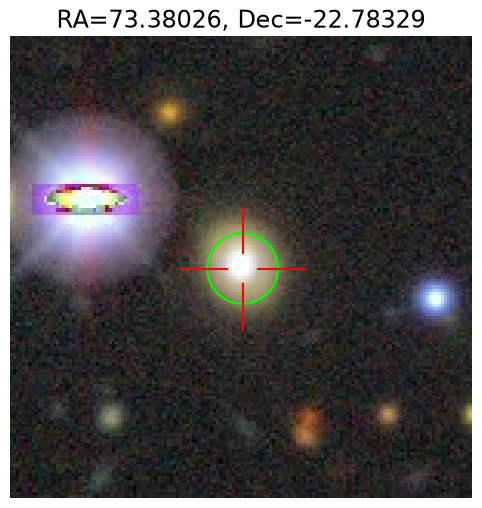

In [5]:
import requests
from io import BytesIO
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# RA, DEC = 73.3802607540275, -22.783294013889787
RA, DEC = 73.3802607540275, -22.783294013889787

# Legacy Survey cutout service
size_pix = 150          # image size in pixels
pixscale = 0.262        # arcsec/pixel (native DECam scale)
layer = "ls-dr10"        # legacy survey data release layer

cutout_url = (
    f"https://www.legacysurvey.org/viewer/cutout.jpg"
    f"?ra={RA}&dec={DEC}&layer={layer}"
    f"&pixscale={pixscale}&size={size_pix}"
)

resp = requests.get(cutout_url)
resp.raise_for_status()

img = Image.open(BytesIO(resp.content))

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img)

# center of image = target RA/Dec
cx, cy = size_pix / 2, size_pix / 2

# crosshair
crosshair_len = 20
ax.plot([cx - crosshair_len, cx - 5], [cy, cy], color="red", lw=1.5)
ax.plot([cx + 5, cx + crosshair_len], [cy, cy], color="red", lw=1.5)
ax.plot([cx, cx], [cy - crosshair_len, cy - 5], color="red", lw=1.5)
ax.plot([cx, cx], [cy + 5, cy + crosshair_len], color="red", lw=1.5)

# circle marker (radius in pixels, e.g. corresponding to ~3 arcsec)
circle_radius_pix = 3 / pixscale
circ = patches.Circle((cx, cy), circle_radius_pix, fill=False, color="lime", lw=1.5)
ax.add_patch(circ)

ax.set_title(f"RA={RA:.5f}, Dec={DEC:.5f}")
ax.axis("off")
plt.show()

In [7]:
import requests
from astropy.table import Table
from astropy.io import fits
from io import BytesIO

RA, DEC = 73.3802607540275, -22.783294013889787

# tiny box just around the exact position (~2 arcsec half-width)
box_deg = 2 / 3600.0

cat_url = (
    f"https://www.legacysurvey.org/viewer/ls-dr10/cat.fits"
    f"?ralo={RA - box_deg:.6f}&rahi={RA + box_deg:.6f}"
    f"&declo={DEC - box_deg:.6f}&dechi={DEC + box_deg:.6f}"
)

resp = requests.get(cat_url)
resp.raise_for_status()

hdul = fits.open(BytesIO(resp.content))
tab = Table(hdul[1].data)

if len(tab) == 0:
    print("No Legacy Survey source found at this position.")
else:
    # closest match to the exact RA/Dec
    import numpy as np
    dist = np.hypot(tab["ra"] - RA, (tab["dec"] - DEC))
    row = tab[np.argmin(dist)]
    print(row)

release brickid brickname objid brick_primary maskbits fitbits type         ra                dec            ra_ivar       dec_ivar       bx        by                dchisq                ebv          mjd_min           mjd_max      ref_cat        ref_id          pmra     pmdec      parallax  pmra_ivar pmdec_ivar parallax_ivar ref_epoch gaia_phot_g_mean_mag gaia_phot_g_mean_flux_over_error gaia_phot_g_n_obs gaia_phot_bp_mean_mag gaia_phot_bp_mean_flux_over_error gaia_phot_bp_n_obs gaia_phot_rp_mean_mag gaia_phot_rp_mean_flux_over_error gaia_phot_rp_n_obs gaia_phot_variable_flag gaia_astrometric_excess_noise gaia_astrometric_excess_noise_sig gaia_astrometric_n_obs_al gaia_astrometric_n_good_obs_al gaia_astrometric_weight_al gaia_duplicated_source gaia_a_g_val gaia_e_bp_min_rp_val gaia_phot_bp_rp_excess_factor gaia_astrometric_sigma5d_max gaia_astrometric_params_solved   flux_g   flux_r    flux_i    flux_z    flux_w1   flux_w2   flux_w3   flux_w4  flux_ivar_g flux_ivar_r flux_ivar_i flux_

In [9]:
from astroquery.ipac.irsa import Irsa
from astropy.coordinates import SkyCoord
import astropy.units as u

RA, DEC = 73.3802607540275, -22.783294013889787

coord = SkyCoord(ra=RA, dec=DEC, unit="deg", frame="icrs")

# AllWISE Source Catalog cone search
radius = 5 * u.arcsec

result = Irsa.query_region(
    coordinates=coord,
    catalog="allwise_p3as_psd",   # AllWISE Source Catalog
    spatial="Cone",
    radius=radius,
)

if len(result) == 0:
    print("No WISE match found within radius.")
else:
    cols = ["designation", "ra", "dec", "w1mpro", "w2mpro", "w3mpro", "w4mpro"]
    cols = [c for c in cols if c in result.colnames]
    result[cols].pprint()

    designation         ra         dec     w1mpro w2mpro w3mpro w4mpro
                       deg         deg      mag    mag    mag    mag  
------------------- ---------- ----------- ------ ------ ------ ------
J045331.26-224659.6 73.3802787 -22.7832364 13.204 12.374 10.038  7.764


In [ ]:
import requests
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.visualization import astropy_mpl_style

# 1. Define target parameters (Example: NGC 4535)

SIZE_PX = 500
PIXSCALE = 0.262
LAYER = "ls-dr10"
BANDS = "g"

# 2. Construct the Legacy Survey DR10 FITS API URL
base_url = "https://legacysurvey.org"
params = {
    "ra": RA,
    "dec": DEC,
    "size": SIZE_PX,
    "pixscale": PIXSCALE,
    "layer": LAYER,
    "bands": BANDS
}

print(f"Requesting DR10 FITS cutout for RA={RA}, DEC={DEC}...")

# 3. Download the FITS file
response = requests.get(base_url, params=params)

if response.status_code == 200:
    filename = f"legacy_survey_dr10_{BANDS}.fits"
    with open(filename, "wb") as f:
        f.write(response.content)
    print(f"Successfully saved to {filename}")
    
    # 4. Open and display the FITS image using astropy
    plt.style.use(astropy_mpl_style)
    with fits.open(filename) as hdul:
        # Print file structure information
        hdul.info()
        
        # Get image data
        img_data = hdul[0].data
        
        # Plot the data
        plt.figure(figsize=(6, 6))
        plt.imshow(img_data, cmap="viridis", origin="lower")
        plt.colorbar(label="Flux")
        plt.title(f"DR10 Cutout ({BANDS}-band) at RA={RA}, DEC={DEC}")
        plt.grid(False)
        plt.show()
else:
    print(f"Failed to fetch image. HTTP Status Code: {response.status_code}")


Requesting DR10 FITS cutout for RA=73.3802607540275, DEC=-22.783294013889787...
Successfully saved to legacy_survey_dr10_g.fits


OSError: No SIMPLE card found, this file does not appear to be a valid FITS file. If this is really a FITS file, try with ignore_missing_simple=True

In [15]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
import glob as glob
import os

In [10]:
data_dir = "/Users/ani/work/projects/fast-transients/tidez/data/candidates"
glob_pattern = f"{test_data_dir}/*.fits"
data = glob.glob(glob_pattern)

print(f"Found {len(data)} files in {data_dir}")

Found 12 files in /Users/ani/work/projects/fast-transients/tidez/data/candidates


In [16]:
test_data = np.random.choice(data)
print(f"Using {os.path.basename(test_data)} for testing")

Using 34_A202502061452447m014625.fits for testing


In [23]:
with fits.open(test_data) as hdul:
    data = hdul[1].data
    header = hdul[1].header

In [21]:
data

FITS_rec([(0, 'c4d_250206_083511_xxx_g_v1', 'c4d_170301_085746_xxx_g_ls9', 60712.35777604, 'g', 'N3', 1945.02263879, 3864.61664201, 1945.02263879, 3864.61664201, 1922.58854528, 3847.65822502, 1945.07076652, 3864.0536568 ,       nan,       nan,         nan,    nan,    nan,        nan, [[ 1.07283020e+00,  5.99287415e+00, -4.80758667e-01, ..., -6.52766418e+00, -1.47305298e+00,  1.81259155e+00], [ 4.04631042e+00, -2.14268494e+00, -5.15325928e+00, ..., -6.06671143e+00, -3.71557617e+00, -1.41494751e-01], [-4.80593872e+00,  5.85191345e+00,  1.45777893e+01, ...,  9.12049866e+00, -3.66625977e+00, -1.30939331e+01], ..., [-2.46170044e+00, -6.46162415e+00,  5.03643799e+00, ..., -8.08561707e+00, -4.05303955e-01, -2.27676392e-01], [-4.31753540e+00,  1.17961121e+00, -2.73992920e+00, ...,  1.00622864e+01,  1.59325867e+01, -1.08917236e-01], [-5.17541504e+00,  7.74427795e+00, -2.79708862e-01, ..., -5.41632080e+00, -5.06571960e+00,  8.70748901e+00]], [[ 2.45246261e-01, -1.82039440e-01, -6.93510830e-01, .

In [24]:
header

XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =               351677 / length of dimension 1                          
NAXIS2  =                   82 / length of dimension 2                          
PCOUNT  =                    0 / number of group parameters                     
GCOUNT  =                    1 / number of groups                               
TFIELDS =                   37 / number of table fields                         
TTYPE1  = 'INDEX   '                                                            
TFORM1  = 'K       '                                                            
TTYPE2  = 'SCIENCE_NAME'                                                        
TFORM2  = '27A     '                                                            
TTYPE3  = 'TEMPLATE_NAME'   

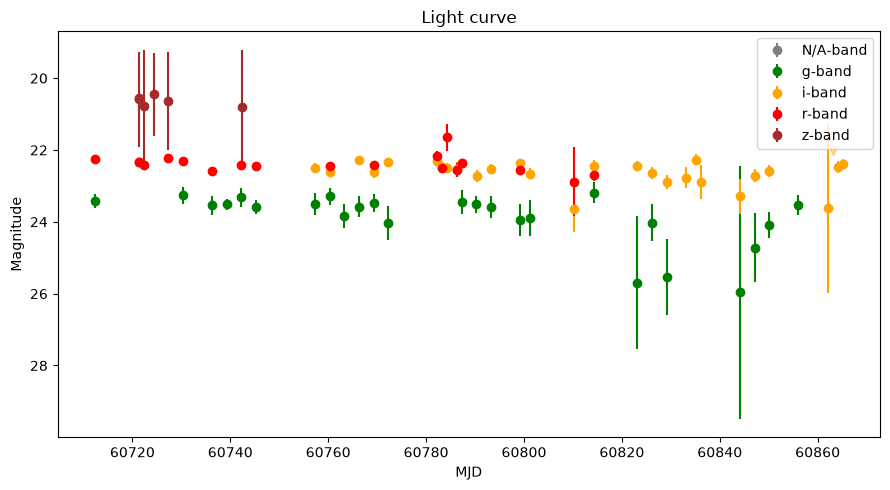

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

with fits.open(test_data) as hdul:
    data = hdul[1].data

mjd = data['MJD_OBS']
filt = data['FILTER']
mag = data['MAG_FPHOT']
magerr = data['MAGERR_FPHOT']
limmag5 = data['LIM_MAG5']
status = data['STATUS_FPHOT']

filters = np.unique(filt)
colors = {'g': 'green', 'r': 'red', 'i': 'orange', 'z': 'brown'}

fig, ax = plt.subplots(figsize=(9, 5))

for f in filters:
    mask = filt == f
    detected = mask & ~np.isnan(mag) & (magerr > 0)
    nondetected = mask & np.isnan(mag)

    ax.errorbar(mjd[detected], mag[detected], yerr=magerr[detected],
                fmt='o', color=colors.get(f, 'gray'), label=f'{f}-band')

    # plot non-detections as downward-pointing triangles at the 5-sigma limit
    ax.scatter(mjd[nondetected], limmag5[nondetected],
               marker='v', color=colors.get(f, 'gray'), alpha=0.4)

ax.invert_yaxis()  # brighter = up
ax.set_xlabel('MJD')
ax.set_ylabel('Magnitude')
ax.set_title('Light curve')
ax.legend()
plt.tight_layout()
# plt.savefig('lightcurve.png', dpi=150)
plt.show()